# T014 · 结合位点检测

**说明：**本教程属于 TeachOpenCADD 项目。该平台旨在教授领域专属技能，并提供可作为研究项目起点的流程模板。

作者：

* 改编自 Abishek Laxmanan Ravi Shankar，2019 年，于 Volkamer 实验室实习期间完成
* Andrea Volkamer，2020/21，[Volkamer 实验室，Charité](https://volkamerlab.org/)
* Dominique Sydow，2020/21，[Volkamer 实验室，Charité](https://volkamerlab.org/)

## 本教程的目标

蛋白质的结合位点是其功能的关键。本教程将介绍计算结合位点检测工具的基本概念，并以 EGFR 结构为例，使用 [protein.plus](https://proteins.plus/) Web 服务器中的 DoGSiteScorer 进行检测。
此外，我们还将通过计算两组位点中相同残基所占的百分比，将结果与 KLIFS 预定义的结合位点进行比较。

### *理论*部分内容

* 蛋白质结合位点
* 结合位点检测
    * 方法概览
    * DoGSiteScorer
* 与 KLIFS 口袋的比较

### *实践*部分内容

* 使用 DoGSiteScorer 检测结合位点
    * 提交感兴趣的结构
    * 获取 DoGSiteScorer 口袋元数据
    * 选择最合适的口袋
    * 获取最佳结合位点文件内容
    * 检查检测到的口袋
* 比较 DoGSiteScorer 与 KLIFS 口袋
    * 获取 DoGSiteScorer 口袋残基
    * 获取 KLIFS 口袋残基
    * 比较口袋残基的重叠情况

### 参考资料
* Prediction, Analysis, and Comparison of Active Sites [Volkamer <i>et al.</i>, (<b>2018</b>)](https://doi.org/10.1002/9783527806539.ch6g)，收录于 Wiley 出版的专著 Applied Chemoinformatics: Achievements and Future Opportunities
* DoGSiteScorer，[Volkamer <i>et al.</i>, <i>J.Chem.Inf.Model</i>, (<b>2012</b>), 52(2):360-372](https://pubmed.ncbi.nlm.nih.gov/22148551/)
* [ProteinsPlus](https://proteins.plus/)：大分子结构分析 Web 门户。[Fährrolfes <i>et al.</i>, <i>NAR</i>, (<b>2017</b>), 3;45(W1)](https://pubmed.ncbi.nlm.nih.gov/28472372/)
* [KLIFS](https://klifs.net/)：结构激酶-配体相互作用数据库。[Kanev <i>et al.</i>, <i>NAR</i>, (<b>2021</b>), 49(D1):D562-D569](https://academic.oup.com/nar/article/49/D1/D562/5934416)

In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install teachopencadd --no-deps -q
    !teachopencadd -d 14
    %pip uninstall teachopencadd -y -q
    %pip install -qr requirements.txt

## 理论

### 蛋白质结合位点

大多数生物过程都由分子间可逆或不可逆的结合所调控。对于与特定疾病相关的治疗靶点，了解其结合位点（即蛋白质发挥功能的关键所在）对于设计新药至关重要。

根据现有数据（例如没有蛋白质-配体复合物的 X 射线结构），或者当研究者关注变构位点时，就需要使用结合位点检测算法。结合位点（对于酶通常称为活性位点）是三维空间中的空腔，通常位于蛋白质结构表面，可作为配体、多肽或蛋白质的结合（对接）区域。两个结合伙伴要发生相互作用，其形状和物理化学性质必须互补，即符合“钥匙与锁”的原理。

![Binding site example](images/3w32_SP_0_0_scale025.png)

*图 1*：使用 [proteins.plus](https://proteins.plus) 中的 DoGSiteScorer 检测到的 EGFR 激酶结合位点示例（PDB：[3w32](https://www.rcsb.org/structure/3W32)）。蛋白质以蓝色 cartoon 表示，配体以棍状表示（碳原子为灰色），结合位点显示为紫色云状区域（图中为最大的亚口袋 SP_0_0）。

### 结合位点检测

#### 方法概览

如果已知配体信息（即有蛋白质-配体复合物），可以直接将配体周围的蛋白质残基定义为口袋（例如，将距配体原子预定半径范围内的所有蛋白质残基纳入，其中半径可设为 6 Å）。如果没有配体，则可以使用预测工具进行*计算机模拟*口袋检测。这些方法一方面可分为基于几何和基于能量的方法，另一方面可分为基于网格和无网格的方法，如图 2 所示。请注意，近年来已有越来越多基于机器学习或深度学习的方法问世（例如 Jiménez *等人*开发的 [DeepSite](https://doi.org/10.1093/bioinformatics/btx350)，发表于 Bioinformatics，2017，33(19)，3036–3042）。

![Binding site detection methods](images/Figure2_DetectionMethods_scale05.png)

*图 2*：结合位点检测方法可分为基于几何或基于能量的方法，以及基于网格或无网格的方法。图片摘自 Prediction, Analysis, and Comparison of Active Sites，[Volkamer <i>et al.</i>, (<b>2018</b>)](https://doi.org/10.1002/9783527806539.ch6g)，收录于 Wiley 出版的 Applied Chemoinformatics: Achievements and Future Opportunities。

**基于几何的方法**分析分子表面的形状以定位空腔，并考虑蛋白质表面原子的三维空间排布。**基于能量的方法**记录探针或分子片段与蛋白质之间的相互作用，据此将有利的能量响应区域判定为口袋。这两类方法都可以在蛋白质的笛卡尔**网格**表示中执行（即检查各网格点的环境），也可以不使用网格（即采用**无网格**方法）。

下面简要介绍四种类别各自的一个例子：

* *几何、基于网格的方法*：[**LIGSITE**](https://doi.org/10.1016/s1093-3263(98)00002-3)（Hendlich，*等人*，J Mol Graph Model.，1997，15(6):359-63, 389）在目标蛋白质上铺设笛卡尔网格（例如网格间距为 1 Å）。随后沿七个方向（x、y、z 轴以及四条立方体对角线）扫描每个网格点，并记录每个点上的蛋白质-溶剂-蛋白质（PSP）事件数量（两侧均由蛋白质限制的射线数）。最后，将被包埋的网格点（即 PSP 值较高的点）聚类成口袋。
* *几何、无网格方法*：[**SURFNET**](https://doi.org/10.1016/0263-7855(95)00073-9)（Laskowski，J Mol Graph.，1995，13(5):323-30, 307-8）直接在蛋白质表面每对原子的中间放置球体。如果探针与附近任一原子发生碰撞，就缩小其半径，直到不再重叠。最终得到的探针球定义了空腔。
* *能量、基于网格的方法*：[**DrugSite**](https://doi.org/10.11234/GI1990.15.2_31)（An，*等人*，Genome Informatics，2004，15(2): 31–41）将蛋白质置于笛卡尔网格中，并在每个网格点放置碳探针。随后计算探针与 8 Å 范围内蛋白质环境之间的范德华能。能量不利的网格点（即超过基于整个网格平均能量和标准差设定的能量阈值的点）会被剔除。最后，将满足阈值条件的网格点合并为口袋。
* *能量、无网格方法*：在基于**对接**的方法中，将分子片段（或小分子）对接到目标蛋白质上（放置并评分；关于对接的更多信息请参见 talktorial T015）。之后，根据结合到特定区域的片段数量来确定口袋。

#### DoGSiteScorer

本教程将使用 [protein.plus](https://proteins.plus/) 中的 DoGSiteScorer 功能来检测并评分目标蛋白质的口袋。因此，下面会更详细地介绍该算法（图 3 以示意图说明了相关流程）。

* *口袋检测*：DoGSiteScorer 使用**基于几何的网格算法**检测口袋。首先将蛋白质置于笛卡尔网格中，根据网格点是否落入任一蛋白质原子的范德华半径内，将其标记为 0（空闲）或 1（占据）。然后调用图像处理中的边缘检测算法——**高斯差分滤波器**（Difference of Gaussian filter，因此称为 DoGSite）来识别蛋白质表面的凸起区域（即球状物体容易放置的位置）。根据特定的阈值条件选取强度最高的网格点，先聚类为亚口袋，再合并成口袋。
* *描述符计算*：根据口袋的网格表示及其周围的蛋白质原子，推导出描述口袋性质的指标。这些性质包括口袋体积、表面积或深度（直接由各网格点的性质计算），以及疏水性、可用氢键供体/受体数量或氨基酸数量（根据邻近蛋白质残基计算）。
* *成药性评估*：该工具还内置了成药性预测器。[成药性](https://en.wikipedia.org/wiki/Druggability)可定义为疾病相关靶点结合并可能受低分子量化合物调节的能力（有时也称为配体性）。DoGSiteScorer 使用支持向量机（SVM）模型预测成药性。该模型在可免费获取的非冗余成药性数据集（NR）DD 上训练和测试。DD 包含 1069 个靶点，并将每个靶点划分为三类：可成药、难成药或不可成药。

    关于 DoGSiteScorer 成药性模型的更多细节，请参见 [Volkamer <i>et al.</i>, J. Chem. Inf. Model., 2012, 52, 2, 360–372](https://pubs.acs.org/doi/10.1021/ci200454v)。关于*成药性*概念本身，可参阅 Hopkins 和 Groom 的文章：[The druggable genome](https://www.nature.com/articles/nrd892)，Nat Rev Drug Discov 1, 727–730 (2002)。

![DoGSiteScorer methodology](images/3w32_DoGSite_Overview_scale05.png)

*图 3*：DoGSiteScorer 各步骤示意图：A. 口袋检测、B. 描述符计算、C. 成药性评估。此图根据 [Volkamer <i>et al.</i>, J. Chem. Inf. Model., **2012**, 52(2), 360–372](https://pubs.acs.org/doi/10.1021/ci200454v) 和 [Volkamer <i>et al.</i>, J. Chem. Inf. Model., **2010**, 50(11), 2041–2052](https://pubs.acs.org/doi/10.1021/ci100241y) 重新编绘。

### 与 KLIFS 口袋的比较

获得 DoGSiteScorer 检测的目标结合位点后，可以将其与其他方法的结果进行比较，以验证预测结果。这里，我们使用 KLIFS API，将 DoGSiteScorer 结果与目标激酶结构的 KLIFS 结合口袋定义进行比较（更多信息请参见 **Talktorial T012**）。

**KLIFS 口袋定义简介：**
[KLIFS](https://klifs.net/)（Kinase-Ligand Interaction Fingerprints and Structures，激酶-配体相互作用指纹与结构）数据库是一个结构资源库，收录了 3600 多个人和小鼠激酶结构。经过整理的 KLIFS 数据可用于系统分析所有激酶结构和结合位点、结合配体及蛋白质-配体相互作用。KLIFS 提供了激酶中常见结构基序的命名规则（例如 DFG-in/out、铰链区等），并通过精细的多序列比对，将所有已知激酶的结合位点映射到 85 个残基上。这样就可以比较不同激酶抑制剂的相互作用模式，例如识别决定激酶-抑制剂选择性的关键相互作用。

本教程将查询 KLIFS API，返回感兴趣的特定蛋白激酶结构的结合口袋，以供后续分析。

## 实践

本实践部分将介绍如何通过 [proteins.plus](https://proteins.plus) 服务器调用 DoGSiteScorer，对目标蛋白质进行结合位点检测。

导入所有必需的库。

In [2]:
import io
from pathlib import Path
import time
import gzip

import requests
from matplotlib_venn import venn2
import matplotlib.pyplot as plt
import pandas as pd
from biopandas.pdb import PandasPdb
import pypdb
import nglview

from opencadd.databases.klifs import setup_remote

pd.set_option("display.max_columns", 50)

/opt/miniconda3/envs/T014_3110/lib/python3.11/site-packages/swagger_spec_validator/validator12.py:18: DeprecationWarning: jsonschema.RefResolver is deprecated as of v4.18.0, in favor of the https://github.com/python-jsonschema/referencing library, which provides more compliant referencing behavior as well as more flexible APIs for customization. A future release will remove RefResolver. Please file a feature request (on referencing) if you are missing an API for the kind of customization you need.
  from jsonschema import RefResolver
/opt/miniconda3/envs/T014_3110/lib/python3.11/site-packages/swagger_spec_validator/validator12.py:18: DeprecationWarning: jsonschema.RefResolver is deprecated as of v4.18.0, in favor of the https://github.com/python-jsonschema/referencing library, which provides more compliant referencing behavior as well as more flexible APIs for customization. A future release will remove RefResolver. Please file a feature request (on referencing) if you are missing an A

将本教程的路径 (`HERE`) 及其数据文件夹 (`DATA`) 加入全局变量。

In [3]:
HERE = Path(_dh[-1])
DATA = HERE / "data"
DATATMP = DATA / "_tmp"
DATATMP.mkdir(parents=True, exist_ok=True)

### 使用 DoGSiteScorer 检测结合位点
首先，定义一个函数，向服务器查询感兴趣的蛋白质。
关于 REST DoGSite3 API 的信息，请见[此处](https://proteins.plus/help/dogsite3_rest)。

In [4]:
def submit_dogsite3_job_with_pdbid(pdb_code, chain_id, ligand=""):
    """
    Submit a PDB ID to ProteinsPlus DoGSite3 API and get back the job URL.

    Parameters
    ----------
    pdb_code : str
        4-letter valid PDB ID, e.g. '3w32'.
    chain_id : str
        Chain ID, e.g. 'A'.
    ligand : str
        Name of ligand bound to PDB structure with pdb_id, e.g. 'W32_A_1101'.

    Returns
    -------
    str
        The job location URL (relative ID) to poll for results.
    """
    url = "https://proteins.plus/api/dogsite3_rest"
    payload = {
        "dogsite3": {
            "pdbCode": pdb_code,
            "analysisDetail": "1",  # include subpockets
            "bindingSitePredictionGranularity": "1",  # include druggability scores
            "ligand": ligand,
            "chain": chain_id,
            "ligandBias": "0",  # default: no ligand bias
        }
    }
    headers = {"Content-Type": "application/json", "Accept": "application/json"}

    r = requests.post(url, json=payload, headers=headers)
    r.raise_for_status()
    resp = r.json()

    # Should return status_code + location (job ID)
    if "location" in resp:
        return resp["location"]
    else:
        raise RuntimeError("Unexpected response from DoGSite3 submission: %r" % resp)

#### 提交感兴趣的结构

指定感兴趣的蛋白质。这里以 EGFR 激酶结构为例，详情见对应的 PDB 条目：[3w32](https://www.rcsb.org/structure/3W32)。

In [5]:
pdb_id = "3w32"
chain_id = "A"
# Ligand id manually looked-up from DoGSiteScorer within proteins.plus
# Note that it is generally composed of [pdb_lig_id]_[chain_id]_[pdb_residue_id]
ligand_id = "W32_A_1101"

提交查询，并获取 Web 服务器上的任务位置（URL），以便后续查看。

In [6]:
job_location = submit_dogsite3_job_with_pdbid(pdb_id, chain_id, ligand_id)
job_location

'https://proteins.plus/api/dogsite3_rest/f4AQNSrkroLhcSk11p94Zfh5'

#### 获取 DoGSiteScorer 口袋元数据
现在定义一个函数，用于收集服务器返回的全部数据，并将其存储到 pandas `DataFrame` 中。

In [7]:
def get_dogsitescorer_metadata(job_location, attempts=30):
    """
    Get results from a DoGSiteScorer query, i.e., the binding sites which are found over the protein surface,
    in the form of a table with the details about all detected pockets.

    Parameters
    ----------
    job_location : str
        Consists of the location of a finished DoGSiteScorer job on the proteins.plus web server.
    attempts : int
        The time waiting for the feedback from DoGSiteScorer service.

    Returns
    -------
    pandas.DataFrame
        Table with metadata on detected binding sites.
    """

    print(f"Querying for job at URL {job_location}...", end="")

    while attempts:
        # Get job results
        result = requests.get(job_location)
        result.raise_for_status()
        # Get URL of result table file
        response = result.json()
        if "result_table" in response:
            result_file = response["result_table"]
            break
        attempts -= 1
        print(".", end="")
        time.sleep(10)
    # Get result table (as string)
    result_table = requests.get(result_file).text
    # Load the table (csv format using "\t" as separator) with pandas DataFrame
    # We cannot load the table from a string directly but from a file
    # Use io.StringIO to wrap this string as file-like object as needed for read_csv method
    # See more: https://docs.python.org/3/library/io.html#io.StringIO
    result_table_df = pd.read_csv(io.StringIO(result_table), sep="\t").set_index("name")

    return result_table_df

从 DoGSiteScorer Web 服务器获取检测到的所有口袋，并返回一个包含口袋描述符信息的 DataFrame。

In [8]:
metadata = get_dogsitescorer_metadata(job_location)
metadata.head()

Querying for job at URL https://proteins.plus/api/dogsite3_rest/f4AQNSrkroLhcSk11p94Zfh5...

,lig_cov,poc_cov,lig_name,4A_crit,ligSASRatio,volume,enclosure,surface,lipoSurface,depth,surf/vol,lid/hull,ellVol,ell_c/a,ell_b/a,surfGPs,lidGPs,hullGPs,siteAtms,accept,donor,posAtms,negAtms,aromat,hydroAtms,...,GLY,HIS,ILE,LEU,LYS,MET,PHE,PRO,SER,THR,TRP,TYR,VAL,A,C,G,U,I,N,DA,DC,DG,DT,DN,UNK
name,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
P_1,89.74360,99.66560,W32_A_1101,1,0.121808,306.176,0.938650,376.060,244.070,15.71750,1.22825,0.061350,377.02800,0.081347,0.116841,459,30,489,61,10,10,1,0,5,34,...,1,0,2,7,1,2,2,0,0,2,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
P_2,0.00000,0.00000,none,0,0.000000,151.552,0.976654,378.645,212.224,9.76524,2.49845,0.023346,84.03600,0.202921,0.278810,251,6,257,41,9,5,0,0,0,20,...,0,0,1,4,1,0,0,1,2,2,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
P_3,0.00000,0.00000,none,0,0.000000,84.992,0.923077,244.361,151.512,6.54828,2.87510,0.076923,16.12450,0.386256,0.481409,132,11,143,27,6,3,1,1,0,18,...,1,0,0,1,1,1,1,0,0,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0
P_4,0.00000,0.00000,none,0,0.000000,76.800,0.875000,289.430,200.108,6.14492,3.76863,0.125000,12.47730,0.460315,0.577608,112,16,128,26,7,1,0,2,1,14,...,1,0,0,1,1,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
P_5,7.69231,3.30579,W32_A_1101,1,0.121808,61.952,0.828829,258.652,145.068,6.64530,4.17504,0.171171,8.06223,0.302690,0.332725,92,19,111,26,6,5,2,1,1,10,...,2,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0


In [9]:
metadata.columns

Index(['lig_cov', 'poc_cov', 'lig_name', '4A_crit', 'ligSASRatio', 'volume',
       'enclosure', 'surface', 'lipoSurface', 'depth', 'surf/vol', 'lid/hull',
       'ellVol', 'ell_c/a', 'ell_b/a', 'surfGPs', 'lidGPs', 'hullGPs',
       'siteAtms', 'accept', 'donor', 'posAtms', 'negAtms', 'aromat',
       'hydroAtms', 'hydrophobicity', 'metal', 'Cs', 'Ns', 'Os', 'Ss', 'Xs',
       'acidicAA', 'basicAA', 'polarAA', 'apolarAA', 'sumAA', 'ALA', 'ARG',
       'ASN', 'ASP', 'CYS', 'GLN', 'GLU', 'GLY', 'HIS', 'ILE', 'LEU', 'LYS',
       'MET', 'PHE', 'PRO', 'SER', 'THR', 'TRP', 'TYR', 'VAL', 'A', 'C', 'G',
       'U', 'I', 'N', 'DA', 'DC', 'DG', 'DT', 'DN', 'UNK'],
      dtype='object')

#### 选择最合适的口袋
初始结果按照各口袋的体积排序。
我们希望重点查看包含配体的口袋（参见配体覆盖列 ``lig_cov``），并且配体对其覆盖程度最高的口袋（口袋覆盖率 ``poc_cov``）。

为便于查看，先从 DataFrame 中删除几列。

In [10]:
metadata = metadata[
    [
        "lig_cov",
        "poc_cov",
        "lig_name",
        "volume",
        "enclosure",
        "surface",
        "depth",
        "surf/vol",
        "accept",
        "donor",
        "hydrophobicity",
        "metal",
    ]
]

根据你关注的列对检测到的结合位点排序。

In [11]:
metadata.sort_values(by=["lig_cov", "poc_cov"], ascending=False).head()
# NBVAL_CHECK_OUTPUT

,lig_cov,poc_cov,lig_name,volume,enclosure,surface,depth,surf/vol,accept,donor,hydrophobicity,metal
name,,,,,,,,,,,,
P_1,89.74360,99.66560,W32_A_1101,306.176,0.938650,376.060,15.71750,1.22825,10,10,0.704918,0
P_5,7.69231,3.30579,W32_A_1101,61.952,0.828829,258.652,6.64530,4.17504,6,5,0.576923,0
P_2,0.00000,0.00000,none,151.552,0.976654,378.645,9.76524,2.49845,9,5,0.658537,0
P_3,0.00000,0.00000,none,84.992,0.923077,244.361,6.54828,2.87510,6,3,0.666667,0
P_4,0.00000,0.00000,none,76.800,0.875000,289.430,6.14492,3.76863,7,1,0.692308,0


**注意**：这里我们选择配体覆盖率和口袋覆盖率最高的口袋，以便在后续比较中精确描述该口袋。其他情况下，也可以按 ``hydrophobicity`` 排序（``metadata.sort_values(by='hydrophobicity', ascending=False)``），或按 ``volume`` 等其他指标排序。

定义一个函数，返回符合所选排序条件的口袋 ID（变量名为 ``best_pocket_id``）。

In [12]:
def select_best_pocket(metadata, sorted_by):
    """
    This function uses the defined sorting parameter to identify
    the best pocket among the obtained pockets.

    Parameters
    ----------
    metadata : pd.DataFrame
        Pockets retrieved from the DoGSiteScorer website

    by : str
        Method name(s) to sort table.

    Returns
    -------
    str
        Best binding site name.
    """

    by_methods = ["volume", "lig_cov", "poc_cov"]

    # Sort by the selected method
    if all(elem in by_methods for elem in sorted_by):
        sorted_pocket = metadata.sort_values(sorted_by, ascending=False)
    else:
        raise ValueError(f'Selection method not in list: {", ".join(by_methods)}')

    # Get name of best pocket
    best_pocket_name = sorted_pocket.iloc[0, :].name

    return best_pocket_name

根据选定的排序方式，以编程方式获取最佳口袋的名称。

In [13]:
best_pocket_id = select_best_pocket(metadata, ["lig_cov", "poc_cov"])
best_pocket_id
# NBVAL_CHECK_OUTPUT

'P_1'

#### 获取结合位点文件内容

定义两个辅助函数，分别获取所有口袋 PDB 文件或 CCP4 文件的 URL。然后，只对感兴趣的口袋进一步处理。

请注意，DoGSiteScorer 会为每个口袋返回两种结构（3D）文件格式：

* *pdb*：这些文件包含口袋周围的所有原子/残基。
    * 通过 ``residues`` 访问
    * 命名示例：3w32_P_1``_res.pdb``
* *ccp4*：这些文件包含构成口袋的网格点，也用于表示口袋的*体积*。
    * 通过 ``pockets`` 访问
    * 命名示例：3w32_P_1``_gps.ccp4.gz``

In [14]:
def get_url_for_pockets(job_location, file_type="pdb"):
    """
    Get all pocket file locations for a finished DoGSiteScorer job
    for a selected file type (pdb/ccp4).

    Parameters
    ----------
    job_location : str
        URL of finished job submitted to the DoGSiteScorer web server.
    file_type : str
        Type of file to be returned (pdb/ccp4).

    Returns
    -------
    list
        List of all respective pocket file URLs.
    """

    # Get job results
    result = requests.get(job_location)

    if file_type == "pdb":
        # Get pocket residues
        return result.json()["residues"]
    elif file_type == "ccp4":
        # Get pocket volumes
        return result.json()["pockets"]
    else:
        raise ValueError(f"File type {file_type} not available.")

In [15]:
def get_selected_pocket_location(job_location, best_pocket, file_type="pdb"):
    """
    Get the selected binding site file location.

    Parameters
    ----------
    job_location : str
        URL of finished job submitted to the DoGSiteScorer web server.
    best_pocket : str
        Selected pocket id.
    file_type : str
        Type of file to be returned (pdb/ccp4).

    Returns
    ------
    str
        URL of selected pocket file on the DoGSiteScorer web server.
    """
    result = []

    # Get URL for all available pdb or ccp4 files
    pocket_files = get_url_for_pockets(job_location, file_type)

    for pocket_file in pocket_files:
        if file_type == "pdb":
            if f"{best_pocket}_res" in pocket_file:
                result.append(pocket_file)
        elif file_type == "ccp4":
            if f"{best_pocket}_gps" in pocket_file:  # previusly _gpsAll
                result.append(pocket_file)

    if len(result) > 1:
        raise TypeError(f'Multiple strings detected: {", ".join(result)}.')
    elif len(result) == 0:
        raise TypeError(f"No string detected.")
    else:
        pass

    return result[0]

获取包含所选口袋残基的 PDB 文件 URL。

In [16]:
selected_pocket_residues_url = get_selected_pocket_location(job_location, best_pocket_id, "pdb")
selected_pocket_residues_url

'https://proteins.plus/results/dogsite3/f4AQNSrkroLhcSk11p94Zfh5/3w32_P_1_res.pdb'

#### 检查检测到的口袋

**口袋描述符**

该算法会返回相应口袋所有已计算描述符的信息。

In [17]:
metadata.loc[best_pocket_id]
# NBVAL_CHECK_OUTPUT

lig_cov              89.7436
poc_cov              99.6656
lig_name          W32_A_1101
volume               306.176
enclosure            0.93865
surface               376.06
depth                15.7175
surf/vol             1.22825
accept                    10
donor                     10
hydrophobicity      0.704918
metal                      0
Name: P_1, dtype: object

**口袋可视化**

我们需要获取包含口袋信息的 ``ccp4`` 文件。首先，获取包含所选口袋体积信息的 ``ccp4`` 文件 URL。

In [18]:
selected_pocket_volume_url = get_selected_pocket_location(job_location, best_pocket_id, "ccp4")
selected_pocket_volume_url

'https://proteins.plus/results/dogsite3/f4AQNSrkroLhcSk11p94Zfh5/3w32_P_1_gps.ccp4.gz'

从 proteins.plus 的 URL 获取网格点坐标。我们不将文件保存到磁盘，而是保存到内存文件（`io.BytesIO`）中。根据 URL 的扩展名可知，这是 gzip 压缩的（`.gz` 扩展名）CCP4 图（`.ccp4`）。具体步骤如下：

1. 将文件从服务器下载到内存。此时数据为 gzip 压缩字节。
2. 使用 `gzip.decompress` 在内存中解压响应内容。
3. 将解压后的数据封装为 `io.BytesIO` 对象，使其表现得像一个已打开的文件。

In [19]:
r = requests.get(selected_pocket_volume_url)
r.raise_for_status()
# Decompress response content and wrap it in a file-like object
memfile = io.BytesIO(gzip.decompress(r.content))

**注意**：如果 NGLviewer 中没有显示口袋体积，请尝试使用 Jupyter Notebook（而不是 Jupyter Lab）运行该 notebook。

In [20]:
def get_pdb_nglviewer(pdb_id):
    # download the PDB file content.
    pdb_file_content = pypdb.get_pdb_file(pdb_id, filetype="pdb")
    # create an nglview structure object from the content
    structure = nglview.TextStructure(pdb_file_content, ext="pdb")
    # set structure viewer
    nglviewer = nglview.show_file(structure)
    return nglviewer

In [21]:
# viewer = nglview.show_pdbid(pdb_id)
viewer = get_pdb_nglviewer(pdb_id)
# Since we are passing bytes with no path or extension
# we need to tell nglview what kind of data this is: ccp4
viewer.add_component(memfile, ext="ccp4")
viewer.center()
viewer

/opt/miniconda3/envs/T014_3110/lib/python3.11/site-packages/pypdb/pypdb.py:497: DeprecationWarning: The `get_pdb_file` function within pypdb.py is deprecated.See `pypdb/clients/pdb/pdb_client.py` for a near-identical function to use
  warnings.warn(


Sending GET request to https://files.rcsb.org/download/3w32.pdb to fetch 3w32's pdb file as a string.


NGLWidget()

In [22]:
viewer.render_image(trim=True, factor=2)
viewer._display_image()

上图显示的内容与直接使用 proteins.plus Web 服务器时相同（见图 1）。

### 比较 DoGSiteScorer 与 KLIFS 口袋

#### 获取 DoGSiteScorer 口袋残基
为了比较自动预测的口袋和人工定义的 KLIFS 口袋，我们需要确定该口袋包含哪些残基。

In [23]:
def get_pocket_residues(pocket_url):
    """
    Gets residue IDs and names of a specified pocket (via URL).

    Parameters
    ----------
    pocket_url : str
        URL of selected pocket file on the DoGSiteScorer web server.

    Returns
    -------
    pandas.DataFrame
        Table of residues names and IDs for the selected binding site.
    """

    # Retrieve PDB file content from URL
    result = requests.get(pocket_url)

    # Get content of PDB file
    pdb_residues = result.text

    # Load PDB format as DataFrame
    ppdb = PandasPdb().read_pdb_from_list(pdb_residues.splitlines(True))
    pdb_df = ppdb.df["ATOM"]

    # Drop duplicates
    # PDB file contains per atom entries, we only need per residue info
    pdb_df.sort_values("residue_number", inplace=True)
    pdb_df.drop_duplicates(subset="residue_number", keep="first", inplace=True)

    return pdb_df[["residue_number", "residue_name"]]

获取所选口袋的残基，并显示前 5 个残基。

In [24]:
dogsite_pocket_residues_df = get_pocket_residues(selected_pocket_residues_url)
dogsite_pocket_residues_df.head()

,residue_number,residue_name
0,718,LEU
8,726,VAL
15,743,ALA
20,744,ILE
28,745,LYS


**另一种口袋可视化**

也可以使用所选口袋的残基，在三维空间中查看口袋。

In [25]:
# Show protein structure as cartoon
viewer = get_pdb_nglviewer(pdb_id)
# Select pocket residues
selection = (
    f":{chain_id} and ({' or '.join(dogsite_pocket_residues_df['residue_number'].astype(str))})"
)
# Show pocket residues as stick
viewer.add_representation("ball+stick", selection=selection, aspectRatio=1.0)
# Show ligand as ball and stick
viewer.add_representation("ball+stick", selection=ligand_id.split("_")[0])
viewer.center()
viewer

Sending GET request to https://files.rcsb.org/download/3w32.pdb to fetch 3w32's pdb file as a string.


/opt/miniconda3/envs/T014_3110/lib/python3.11/site-packages/pypdb/pypdb.py:497: DeprecationWarning: The `get_pdb_file` function within pypdb.py is deprecated.See `pypdb/clients/pdb/pdb_client.py` for a near-identical function to use
  warnings.warn(


NGLWidget()

In [26]:
viewer.render_image(trim=True, factor=2)
viewer._display_image()

#### 获取 KLIFS 口袋残基

我们使用 `opencadd.databases.klifs` 模块提取 KLIFS 数据库定义的结合位点残基（PDB 残基编号）。

KLIFS 及 `opencadd.databases.klifs` 模块的使用详情，请参阅 __Talktorial T012__。

In [27]:
session = setup_remote()

In [28]:
# Get first structure KLIFS ID associated with PDB ID
structures = session.structures.by_structure_pdb_id(pdb_id)
structure_klifs_id = structures["structure.klifs_id"].iloc[0]

In [29]:
# Get the structure's pocket
klifs_pocket_df = session.pockets.by_structure_klifs_id(structure_klifs_id)
# Residue ID: Cast string to int
klifs_pocket_df = klifs_pocket_df.astype({"residue.id": int})
klifs_pocket_df.head()
# NBVAL_CHECK_OUTPUT

,residue.klifs_id,residue.id,residue.klifs_region_id,residue.klifs_region,residue.klifs_color
0,1,716,I.1,I,khaki
1,2,717,I.2,I,khaki
2,3,718,I.3,I,khaki
3,4,719,g.l.4,g.l,green
4,5,720,g.l.5,g.l,green


#### 比较口袋残基的重叠情况

In [30]:
# Get DoGSiteScorer pocket residues as list
dogsite_pocket_residues = dogsite_pocket_residues_df["residue_number"].to_list()
print(
    f"DoGSiteScorer pocket {best_pocket_id} with {len(dogsite_pocket_residues)} residues detected."
)
# Get KLIFS pocket residues as list
klifs_pocket_residues = klifs_pocket_df["residue.id"].to_list()
print(f"KLIFS pocket with {len(klifs_pocket_residues)} residues detected.")

DoGSiteScorer pocket P_1 with 25 residues detected.
KLIFS pocket with 85 residues detected.


In [31]:
overlap = set.intersection(set(dogsite_pocket_residues), set(klifs_pocket_residues))
print(f"Overlap between the two residue sets: {len(overlap)}.")
# NBVAL_CHECK_OUTPUT

Overlap between the two residue sets: 23.


绘制 Venn 图，展示残基重叠情况。

In [32]:
print(f"Residue overlap between the two methods using {best_pocket_id}.")
venn2(
    [set(dogsite_pocket_residues), set(klifs_pocket_residues)],
    set_labels=("DoGSiteScorer", "KLIFS"),
)
plt.show()

Residue overlap between the two methods using P_1.


可以看到，我们从 DoGSiteScorer 选择的亚口袋非常精确。事实上，25 个残基中有 23 个与 KLIFS 定义的口袋（85 个残基）重叠。
不过，KLIFS 口袋整体覆盖的区域更大。
此外，我们也可以将亚口袋 ``P_2``（而不是口袋 ``P_1``）用于同样的比较，看看它与 KLIFS 口袋的重叠情况。

In [33]:
# Get info for largest DoGSiteScorer pocket P_0
new_pocket_id = "P_2"
dogsite_pocket_residues_df_npi = get_pocket_residues(
    get_selected_pocket_location(job_location, new_pocket_id)
)
dogsite_pocket_residues_npi = dogsite_pocket_residues_df_npi["residue_number"].to_list()
print(f"DoGSiteScorer pocket {new_pocket_id} with {len(dogsite_pocket_residues_npi)} detected.")
# NBVAL_CHECK_OUTPUT

DoGSiteScorer pocket P_2 with 16 detected.


Residue overlap between the two methods using P_2.


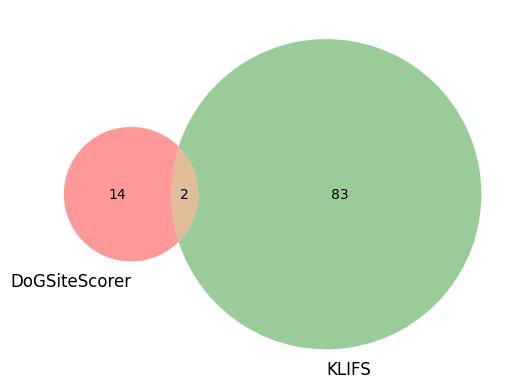

In [34]:
print(f"Residue overlap between the two methods using {new_pocket_id}.")
venn2(
    [set(dogsite_pocket_residues_npi), set(klifs_pocket_residues)],
    set_labels=("DoGSiteScorer", "KLIFS"),
)
plt.show()

## 讨论

本教程介绍了使用 DoGSiteScorer 进行结合位点检测的基本思路，并展示了如何通过 [proteins.plus](https://proteins.plus) 服务器调用该工具。
除了像上文那样研究主要（已知）结合位点外，还可以利用其他预测口袋，针对新的口袋（例如变构口袋或研究较少的口袋）开展药物设计。

可能的局限性：这类算法依据给定的蛋白质结构（X 射线结构）检测口袋。如果同一蛋白质还有其他结构，对那些结构运行算法可能会得到（略有）不同的口袋，例如配体结合引起的构象变化会造成差异。apo 与 holo 结构之间的差别也会影响预测结果。

## 测验

1. 可以使用哪些技术自动检测蛋白质表面的口袋？
2. 自动结合位点检测算法有哪些优点和缺点？
3. 尝试使用另一种 EGFR 激酶结构，并检查预测残基之间的重叠情况。


---

## 来源与许可

本中文译本依据 [TeachOpenCADD 上游版本（提交 `834b9ff59af69e8ba8d42aae23e92c15eb734ef0`）](https://github.com/volkamerlab/teachopencadd/tree/834b9ff59af69e8ba8d42aae23e92c15eb734ef0) 翻译整理。原作采用 [Creative Commons Attribution 4.0 International（CC BY 4.0）](https://creativecommons.org/licenses/by/4.0/) 许可。
